# Overload, decision time and a search model

This notebook follows `01_baseline_and_h1.ipynb` and adds the three analyses the AAMAS paper did not have.

1. **Where were people overloaded?** The study asked six questions after every choice. We test whether they measure one thing and locate overload display by display.
2. **How long would each model take to decide?** We set people's decision times against the work each model's algorithm needs.
3. **Can a model that searches predict choices as well, and foresee time and overload?** We propose a one parameter search model, sample until return, and compare it with every established model on choices, time and premonition of overload.

Every model has one free parameter and the designers' fixed rubric weights, and every prediction is held out, each display predicted from fits to the other displays of its task. These are the development data, so every result here is exploratory, and the claims are tested on open data in the confirmatory step that follows. Every number below was verified twice, by a second run and by an independent implementation written blind from a brief (`verification/`).

**Colab.** Run the cells in order. The first cell clones the repository if it is not already in `/content`. Saved results are shown without the development data. To recompute, upload `Updated_Choice_Overload.csv` to `/content` and set `RECOMPUTE = True` (a few seconds for the overload index and about fifteen minutes for the model analyses with two processes).

In [1]:
import os, sys, json, subprocess, zipfile
from pathlib import Path

REPO = Path(os.environ.get("OVERLOAD_REPO", "/content/overload-prediction"))
DATA = Path(os.environ.get("OVERLOAD_DATA", "/content/Updated_Choice_Overload.csv"))
INDEPENDENT = Path(os.environ.get("OVERLOAD_INDEPENDENT", ""))  # optional, a fresh run of the independent code
RECOMPUTE = False
JOBS = 2

if not REPO.exists():
    if Path("/content/overload-prediction.zip").exists():
        zipfile.ZipFile("/content/overload-prediction.zip").extractall("/content")
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ucchol/overload-prediction.git", str(REPO)],
                       check=True)
sys.path.insert(0, str(REPO / "src"))
os.chdir(REPO)
HAVE_DATA = DATA.exists()

import numpy as np
from IPython.display import Image, Markdown, display
import overload
from overload.engine import plan_digest
print("package", overload.__version__, "| plan digest", plan_digest()[:16])
print("development data", "found" if HAVE_DATA else "not found, saved results are shown")


def section(text, start, stop=None):
    # the part of a markdown report from the heading start up to the heading stop
    a = text.index(start)
    return text[a : text.index(stop, a + 1)] if stop else text[a:]

package 0.1.0 | plan digest 5a073cf3759d2bdf
development data found


## 1. Where were people overloaded?

**Question.** Do the six post-trial questions measure one thing, and which displays raised it?

**Why it matters.** Overload is what the paper must foresee, so we first need a trustworthy measure and a map of where it occurred. The classic test compares one small and one large set between people. Here every person rated all twelve displays, so overload can be located display by display, against each person's own baseline.

**How.**
- The six answers run from 1 to 5. They are aligned so that a higher value always means more overloaded, with satisfaction and certainty reversed.
- Question 6 asks "How uncertain are you about choosing the best option?" while its printed anchors run from very uncertain (1) to very certain (5). Participants answered it as an uncertainty question. Their answers fell with satisfaction and certainty and rose with confusion, frustration and complexity, so it is kept as worded.
- The overload index is the mean of the six aligned answers, in scale points. A display overloaded people when its index was clearly above their own average over all twelve displays.
- Regret is 100 minus the designers' score of the chosen option, so 0 means a best option was chosen. Time is the geometric mean of the seconds on the choice page.
- Intervals come from 1000 resamples of participants. A star marks a difference whose percentile and basic intervals both exclude zero.

# Overload index, development data (exploratory)

## Do the six questions measure one thing?

- Cronbach's alpha within participants 0.87 [0.84, 0.90], over all answers 0.89.
- The first principal component carries 62% of the within participant variance.
- Question 6 against the other answers, raw and within participants: satisfied -0.56, certain -0.57, confused +0.53, frustrated +0.53, complex +0.73.

## Where were people overloaded?

| Trial | Options | Information | Overload index | Against own average | Regret | Best chosen, % | Time, s |
|---|---|---|---|---|---|---|---|
| T1_L8 | 8 | low | 2.19 [2.04, 2.35] | +0.05 [-0.05, 0.14] | 29.4 [25.2, 33.8] | 17 | 42 [35, 50] |
| T2_H8 | 8 | high | 2.27 [2.08, 2.45] | +0.13 [-0.01, 0.25] | 15.7 [10.9, 20.8] | 32 | 50 [42, 58] |
| T3_L16 | 16 | low | 2.43 [2.24, 2.61] | +0.29 [0.18, 0.40] * | 18.8 [12.6, 26.2] | 75 | 52 [45, 60] |
| T4_H16 | 16 | high | 2.28 [2.10, 2.46] | +0.14 [0.02, 0.26] * | 28.3 [23.7, 32.9] | 11 | 71 [60, 85] |
| T5_L32 | 32 | low | 2.65 [2.46, 2.84] | +0.50 [0.38, 0.63] * | 31.2 [23.6, 38.2] | 55 | 68 [57, 81] |
| T6_H32 | 32 | high | 2.46 [2.28, 2.64] | +0.32 [0.20, 0.45] * | 26.5 [22.0, 31.3] | 14 | 70 [59, 85] |
| LT1_L8 | 8 | low | 1.81 [1.68, 1.96] | -0.33 [-0.42, -0.24] * | 22.5 [18.6, 26.6] | 29 | 29 [24, 34] |
| LT2_H8 | 8 | high | 1.93 [1.78, 2.08] | -0.21 [-0.32, -0.10] * | 28.5 [24.7, 32.5] | 28 | 35 [29, 42] |
| LT3_L16 | 16 | low | 1.90 [1.76, 2.06] | -0.24 [-0.34, -0.12] * | 28.3 [24.4, 32.1] | 11 | 33 [28, 39] |
| LT4_H16 | 16 | high | 1.84 [1.68, 1.99] | -0.30 [-0.41, -0.20] * | 21.1 [16.4, 26.0] | 44 | 40 [34, 48] |
| LT5_L32 | 32 | low | 2.02 [1.84, 2.20] | -0.12 [-0.25, 0.01] | 15.2 [11.4, 19.1] | 31 | 37 [32, 43] |
| LT6_H32 | 30 | high | 1.91 [1.75, 2.07] | -0.23 [-0.35, -0.12] * | 14.6 [10.4, 18.7] | 33 | 36 [30, 44] |

## More options and more information

| Task | Measure | 32 minus 8 options | Full minus brief |
|---|---|---|---|
| file | overload (scale points) | +0.33 [0.21, 0.45] * | -0.09 [-0.17, 0.01] |
| file | regret (points) | +6.3 [0.8, 11.5] * | -3.0 [-6.9, 1.3] |
| file | logtime (percent time) | +51.5 [32.0, 74.2] * | +19.2 [7.8, 31.8] * |
| laptop | overload (scale points) | +0.09 [-0.03, 0.21] | -0.02 [-0.09, 0.05] |
| laptop | regret (points) | -10.6 [-14.7, -7.0] * | -0.6 [-3.7, 2.6] |
| laptop | logtime (percent time) | +15.4 [4.6, 27.9] * | +13.6 [3.2, 24.7] * |

## Feelings, errors and effort (within participant and trial correlations)

| | Overload and regret | Overload and log time | Regret and log time |
|---|---|---|---|
| file | +0.05 [-0.04, 0.15] | +0.20 [0.11, 0.28] * | +0.19 [0.06, 0.32] * |
| laptop | +0.13 [0.03, 0.24] * | +0.15 [0.06, 0.24] * | +0.05 [-0.06, 0.15] |
| both | +0.13 [0.06, 0.20] * | +0.08 [0.01, 0.16] * | +0.04 [-0.05, 0.14] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a difference or correlation whose percentile and basic intervals both exclude zero. The overload index runs from 1 (none) to 5 (strong). Time is the geometric mean on the choice page. Development data, exploratory.


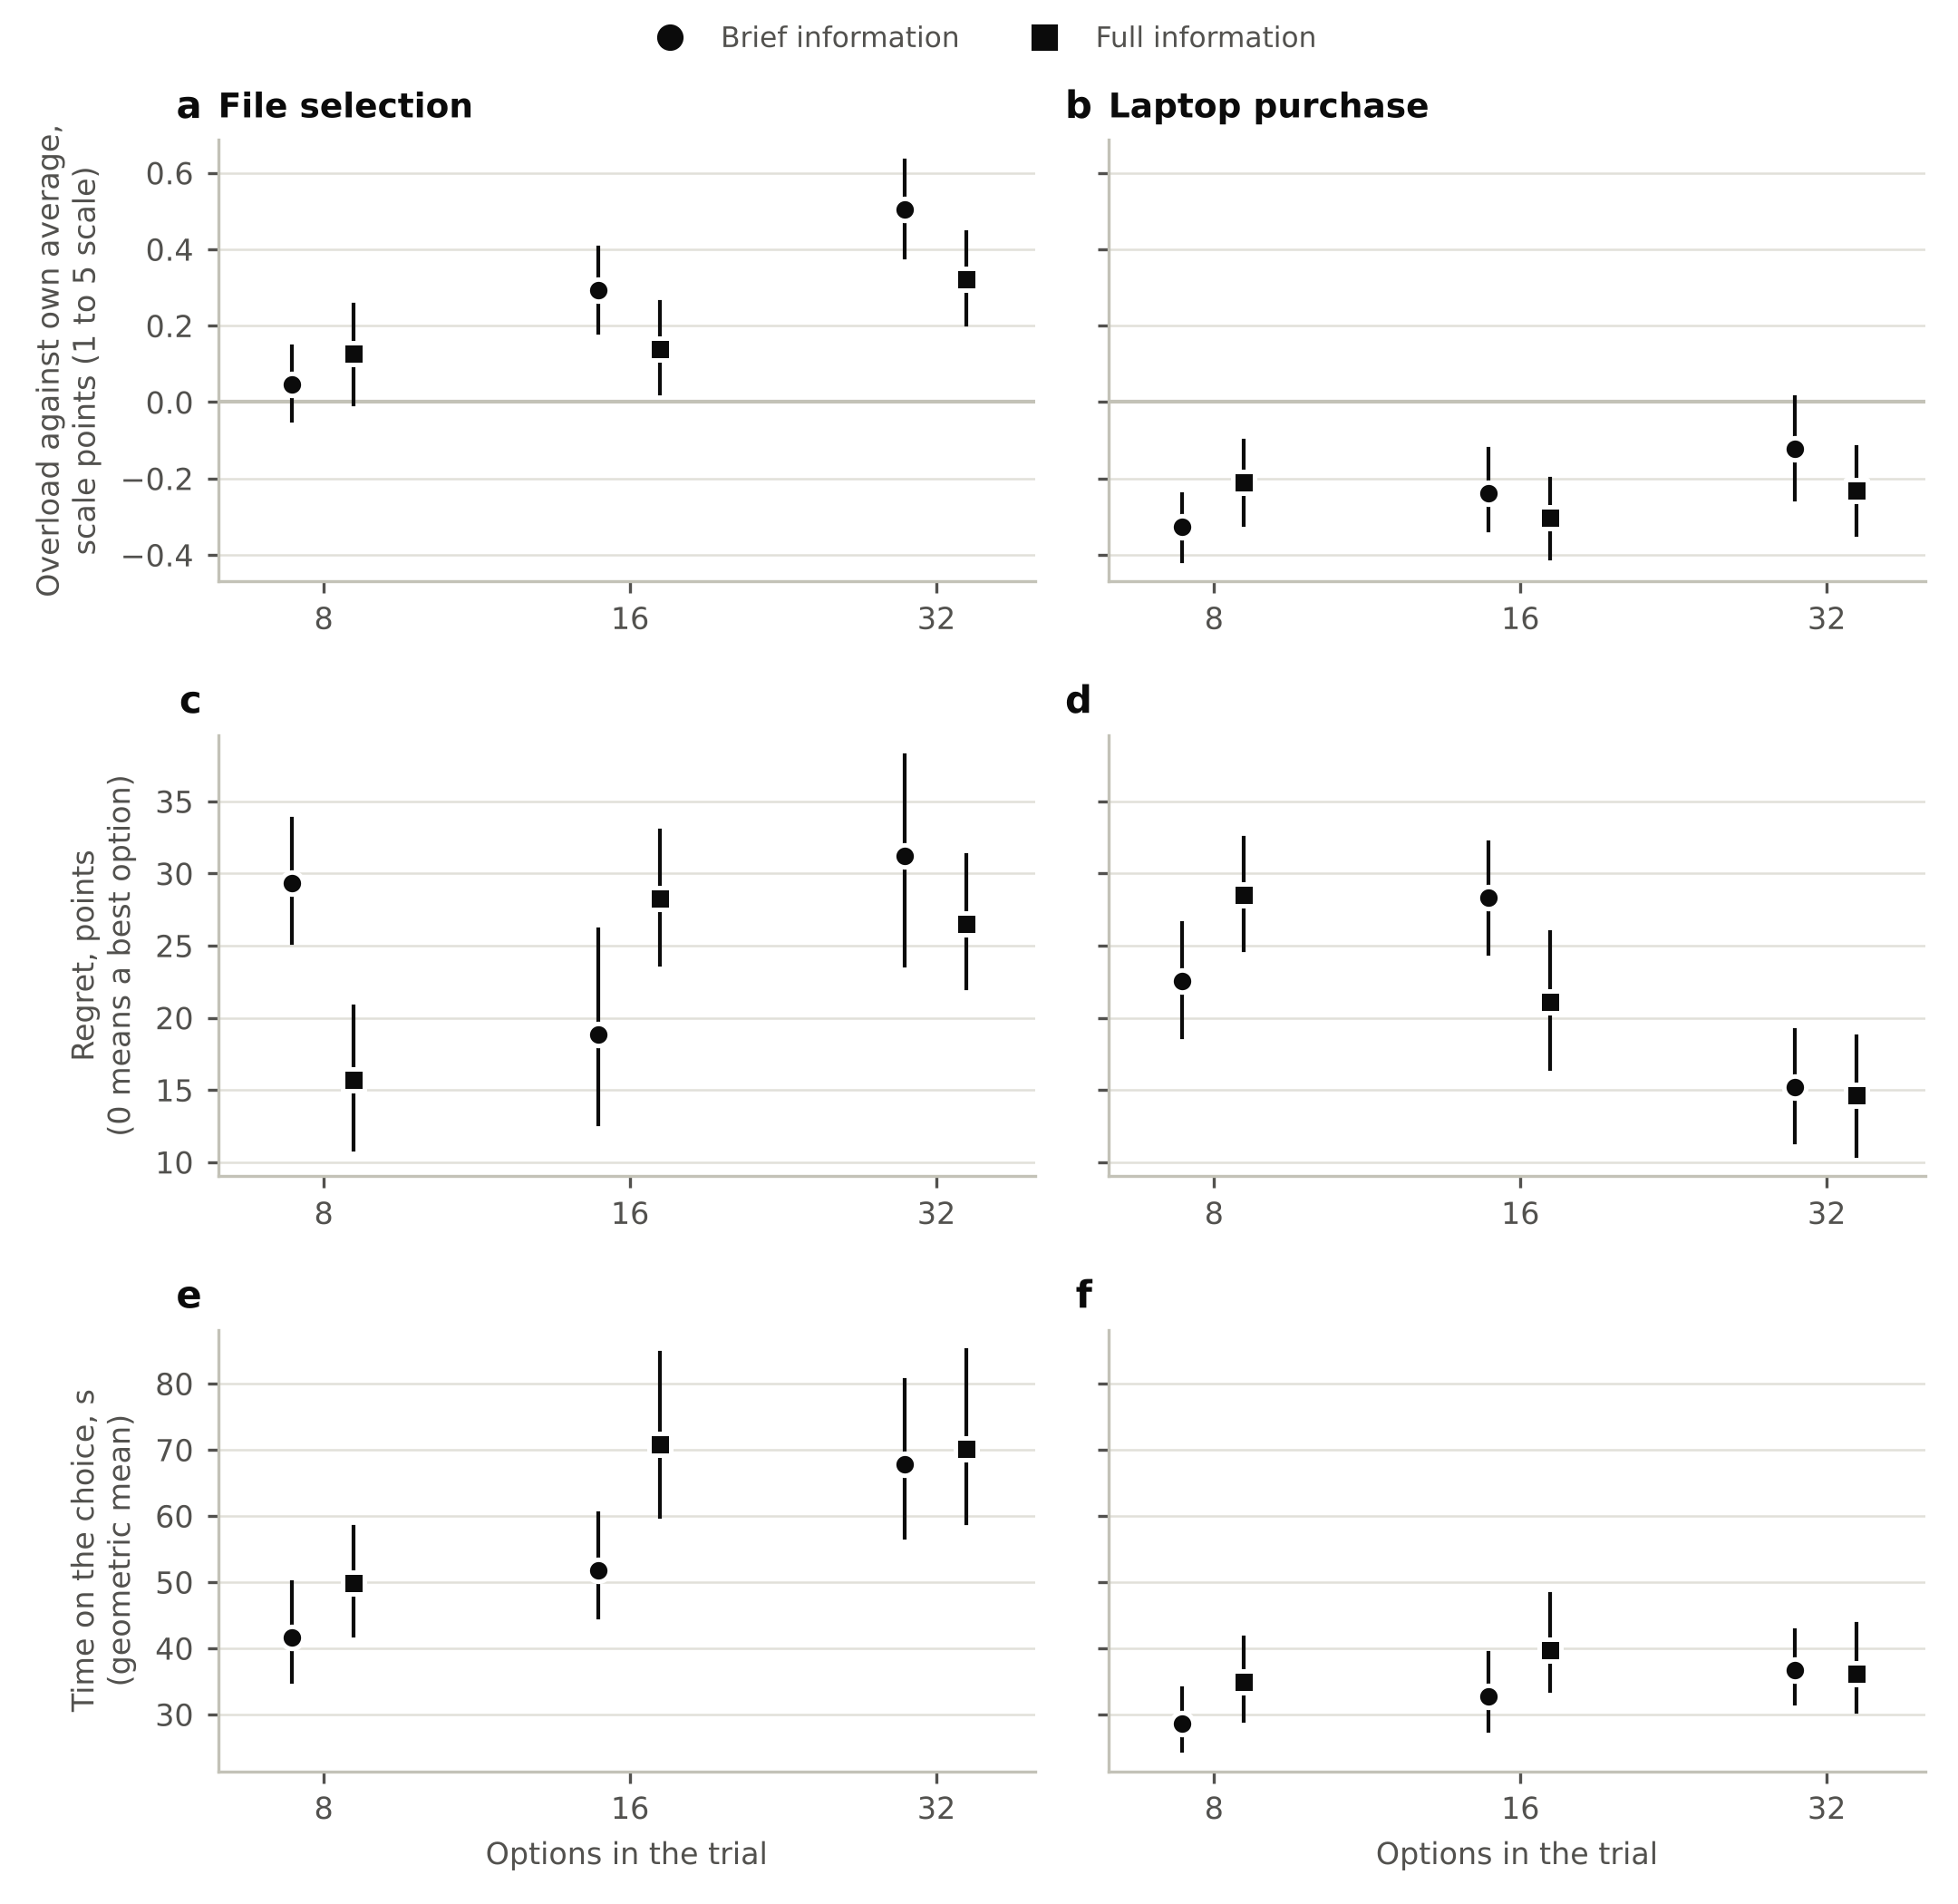

In [2]:
from overload.experiments import overload_index
from overload.figures import figure_overload
out = REPO / "results" / "overload"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    overload_index.run(DATA, out, replicates=1000)
over = json.loads((out / "summary.json").read_text())
figure_overload(over, out / "fig_overload")
display(Markdown((out / "table_overload.md").read_text()))
display(Image(filename=str(out / "fig_overload.png"), width=820))

**Findings.**

1. The six questions measured one thing. Cronbach's alpha within participants was 0.87 [0.84, 0.90], and one component carried 62 percent of the variance.
2. File displays overloaded people more as they grew. Against people's own average, overload rose from +0.05 and +0.13 scale points at 8 files to +0.50 and +0.32 at 32 files, a rise of 0.33 [0.21, 0.45]. Choices also took 52 percent longer [32, 74].
3. Laptop displays never overloaded people. Every laptop display stayed below people's own average, even at 32 laptops (+0.09 [-0.03, 0.21] from 8 to 32 laptops). Choices took only 15 percent longer [5, 28], and they got better, with regret falling by 10.6 points [7.0, 14.7].
4. More information per option did not add overload in either task (-0.09 and -0.02 scale points), although it slowed choices by 19 and 14 percent.
5. Feeling overloaded went with taking longer. On a display where a person felt more overloaded than usual, compared with others on the same display, they also took longer (correlations +0.20 for files and +0.15 for laptops, both clear). The link with regret was weak (+0.05 and +0.13).

**Message.** Overload is not a law of set size. The same people were overloaded by large file displays and not by large laptop displays. A premonition of overload must read the display, not count its options.

## 2. How long would each model take to decide?

**Question.** How much work does each model's algorithm need on each display, and could people have done that work in the time they took?

**Why it matters.** A model that chooses like people should also be fast enough to be how people chose. Time is evidence about the process that choices alone cannot give.

**How.** Each model is written as the elementary steps its algorithm needs (Payne, Bettman and Johnson 1993). One step is reading one attribute value of one option and using it once, adding it into the option's value or comparing it with a rival's.
- CL and QR weigh every value, n m steps for n options and m attributes.
- DbS and MLBA compare every option with every rival on every attribute, n (n - 1) m steps.
- Elimination by aspects checks one aspect across the options still in play, until one option is left.
- Sample until return (Section 3) reads the m attributes of each option it looks at.

Two readings follow.
- **The speed each model needs.** People's time divided by the model's steps is the time each step may take if the model is to finish when people did. Reading a value takes at least one eye fixation, about a quarter of a second, so a model that needs much less per step cannot be how people decided.
- **A held out time law.** Predicted time is a start up time plus a time per step. The two constants are fitted on five displays of a task and predict the sixth, and the typical error is compared with a forecast that ignores the display.

## 2. Time, file

Seconds each model may spend per step to finish when people did.

| Model | T1_L8 | T2_H8 | T3_L16 | T4_H16 | T5_L32 | T6_H32 |
|---|---|---|---|---|---|---|
| People, seconds | 42 | 50 | 52 | 71 | 68 | 70 |
| QR | 5.2 (8) | 1.56 (32) | 3.24 (16) | 1.11 (64) | 2.12 (32) | 0.548 (128) |
| CL | 5.2 (8) | 1.56 (32) | 3.24 (16) | 1.11 (64) | 2.12 (32) | 0.548 (128) |
| DbS_avg | 0.743 (56) | 0.223 (224) | 0.216 (240) | 0.0737 (960) | 0.0684 (992) | 0.0177 (3968) |
| MLBA_avg | 0.743 (56) | 0.223 (224) | 0.216 (240) | 0.0737 (960) | 0.0684 (992) | 0.0177 (3968) |
| EBA | 3.2 (13) | 0.412 (121) | 2.07 (25) | 1.11 (64) | 2.12 (32) | 0.14 (501) |
| SR | 10.2 (4) | 3.05 (16) | 9.61 (5) | 3.35 (21) | 9.38 (7) | 2.38 (29) |
| SR_DbS | 10.3 (4) | 3.09 (16) | 9.59 (5) | 3.32 (21) | 9.2 (7) | 2.41 (29) |
| Accept_read | 8.99 (5) | 2.69 (19) | 9.65 (5) | 1.92 (37) | 15.2 (4) | 6.86 (10) |

Held out predicted seconds, constants fitted on the other five trials.

| Model | T1_L8 | T2_H8 | T3_L16 | T4_H16 | T5_L32 | T6_H32 | Typical error, % | Minus constant (log) |
|---|---|---|---|---|---|---|---|---|
| QR | 55 | 57 | 53 | 60 | 53 | 103 | 22.7 [10.1, 37.5] * | -0.023 [-0.115, 0.078] |
| CL | 55 | 57 | 53 | 60 | 53 | 103 | 22.7 [10.1, 37.5] * | -0.023 [-0.115, 0.078] |
| DbS_avg | 57 | 55 | 55 | 55 | 56 | 152 | 32.0 [16.0, 48.7] * | +0.050 [-0.057, 0.150] |
| MLBA_avg | 57 | 55 | 55 | 55 | 56 | 152 | 32.0 [16.0, 48.7] * | +0.050 [-0.057, 0.150] |
| EBA | 60 | 60 | 57 | 54 | 53 | 68 | 22.3 [15.6, 33.4] * | -0.026 [-0.052, 0.047] |
| SR | 56 | 63 | 52 | 62 | 48 | 73 | 18.8 [12.5, 32.3] * | -0.055 [-0.087, 0.037] |
| SR_DbS | 56 | 63 | 52 | 62 | 48 | 73 | 18.6 [12.2, 32.0] * | -0.057 [-0.091, 0.036] |
| Accept_read | 60 | 63 | 57 | 56 | 51 | 55 | 27.8 [18.1, 36.0] * | +0.017 [-0.012, 0.034] |
| constant | 62 | 60 | 60 | 56 | 57 | 56 | 25.6 [18.0, 32.9] * |  |

## 2. Time, laptop

Seconds each model may spend per step to finish when people did.

| Model | LT1_L8 | LT2_H8 | LT3_L16 | LT4_H16 | LT5_L32 | LT6_H32 |
|---|---|---|---|---|---|---|
| People, seconds | 29 | 35 | 33 | 40 | 37 | 36 |
| QR | 1.19 (24) | 0.726 (48) | 0.68 (48) | 0.414 (96) | 0.382 (96) | 0.201 (180) |
| CL | 1.19 (24) | 0.726 (48) | 0.68 (48) | 0.414 (96) | 0.382 (96) | 0.201 (180) |
| DbS_avg | 0.17 (168) | 0.104 (336) | 0.0454 (720) | 0.0276 (1440) | 0.0123 (2976) | 0.00694 (5220) |
| MLBA_avg | 0.17 (168) | 0.104 (336) | 0.0454 (720) | 0.0276 (1440) | 0.0123 (2976) | 0.00694 (5220) |
| EBA | 0.933 (31) | 1.87 (19) | 0.469 (70) | 0.334 (119) | 0.247 (148) | 0.15 (241) |
| SR | 2.55 (11) | 1.48 (24) | 2 (16) | 1.34 (30) | 1.74 (21) | 0.904 (40) |
| SR_DbS | 2.51 (11) | 1.48 (23) | 2.03 (16) | 1.42 (28) | 1.71 (21) | 0.926 (39) |
| Accept_read | 1.28 (22) | 1.08 (32) | 2.01 (16) | 0.786 (51) | 1.72 (21) | 0.895 (40) |

Held out predicted seconds, constants fitted on the other five trials.

| Model | LT1_L8 | LT2_H8 | LT3_L16 | LT4_H16 | LT5_L32 | LT6_H32 | Typical error, % | Minus constant (log) |
|---|---|---|---|---|---|---|---|---|
| QR | 35 | 33 | 34 | 34 | 35 | 49 | 13.5 [6.2, 26.3] * | +0.029 [-0.033, 0.074] |
| CL | 35 | 33 | 34 | 34 | 35 | 49 | 13.5 [6.2, 26.3] * | +0.029 [-0.033, 0.074] |
| DbS_avg | 35 | 33 | 34 | 33 | 36 | 44 | 12.5 [6.5, 24.6] * | +0.021 [-0.026, 0.060] |
| MLBA_avg | 35 | 33 | 34 | 33 | 36 | 44 | 12.5 [6.5, 24.6] * | +0.021 [-0.026, 0.060] |
| EBA | 35 | 31 | 34 | 34 | 36 | 43 | 12.5 [6.5, 24.2] * | +0.020 [-0.029, 0.056] |
| SR | 34 | 35 | 33 | 35 | 34 | 46 | 10.8 [4.9, 23.6] | +0.006 [-0.057, 0.054] |
| SR_DbS | 34 | 35 | 33 | 35 | 34 | 46 | 11.1 [5.2, 24.1] | +0.008 [-0.056, 0.058] |
| Accept_read | 35 | 35 | 31 | 38 | 32 | 37 | 8.2 [5.3, 18.7] | -0.018 [-0.059, 0.036] |
| constant | 36 | 35 | 35 | 34 | 34 | 34 | 10.2 [6.5, 18.4] * |  |



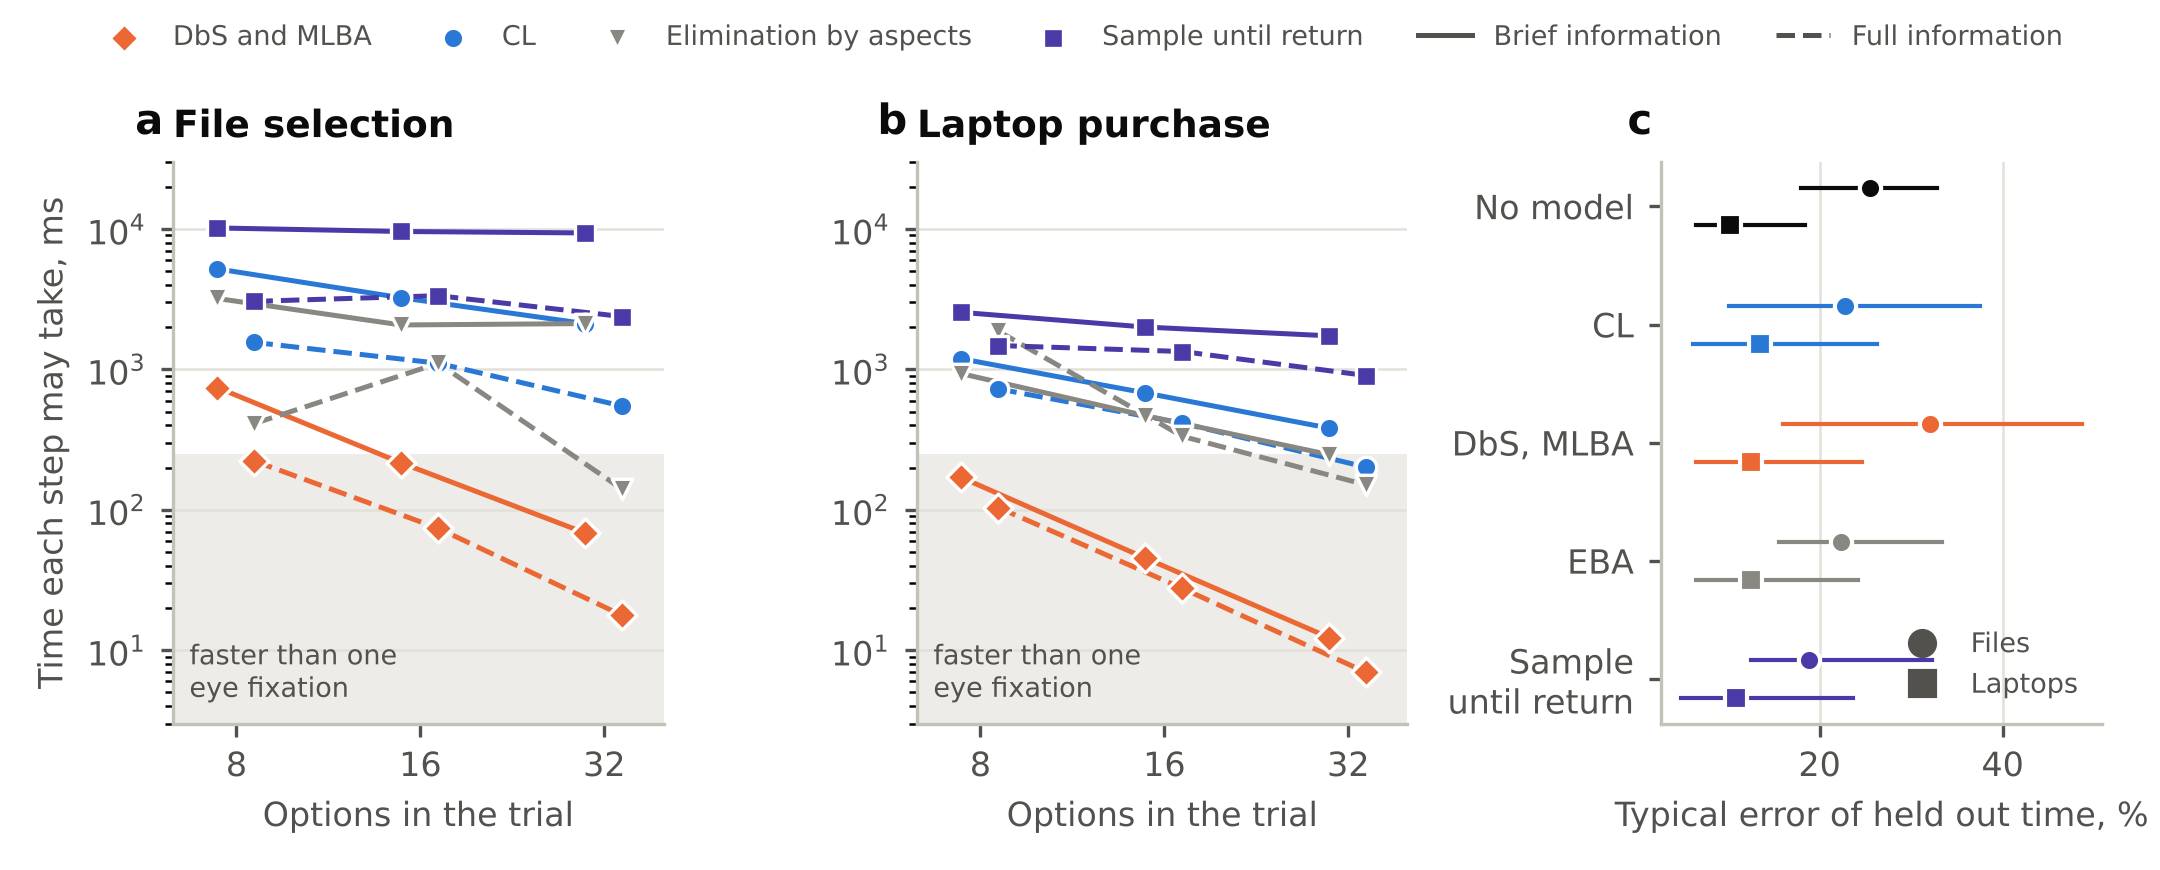

In [3]:
from overload.experiments import process_dev
from overload.figures import figure_time
out = REPO / "results" / "process_dev"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    process_dev.run(DATA, out, replicates=1000, jobs=JOBS)
proc = json.loads((out / "summary.json").read_text())
tables = (out / "tables.md").read_text()
display(Markdown(section(tables, "## 2. Time, file", "## 3. Premonition")))
figure_time(proc, out / "fig_time")
display(Image(filename=str(out / "fig_time.png"), width=900))

**Findings.**

1. People were quick. A laptop choice took 29 to 40 seconds whatever the size of the display, and a file choice 42 to 71 seconds.
2. The comparison models would have to be impossibly fast. To finish when people did on the two 32 laptop displays, DbS and MLBA would have to make each comparison in 12 and 7 milliseconds, 20 to 36 times faster than one eye fixation. On the two 32 file displays they would need 68 and 18 milliseconds.
3. CL would need 0.38 and 0.20 seconds per value on the 32 laptop displays, about one fixation per value with no time left to weigh or decide.
4. Sample until return needs 0.9 to 2.6 seconds for each value it reads on laptop displays, a pace a person can keep.
5. The held out time law could not separate the models. With six displays per task, no model predicted time clearly better than a forecast that ignores the display (sample until return 18.8 percent typical error for files and 10.8 percent for laptops, against 25.6 and 10.2 percent).

**Message.** The clock rules out exhaustive comparison. Whatever people did, they did not compare every option with every other, and they could barely have read every value. A model of how people decide has to stop early.

## 3. A model that searches. Sample until return

**The idea.** Attention moves from option to option. It is drawn to attractive options, with probability proportional to exp(lambda v), where v are the same rubric values CL uses and lambda is the one free parameter. When attention comes back to an option it has already visited, that option is chosen.

**Why this model.**
- In choices among many options, attention is drawn to valuable options (Krajbich and colleagues), and coming back to an option is a natural sign that it stands out.
- It needs no knowledge of the best option and no threshold, only one sensitivity, like CL.
- Everything follows in closed form. With q = softmax(lambda v), the chance that option i is chosen is P(i) = q_i² ∫ t e^(-t) ∏_(j≠i) (1 + q_j t) dt, and the expected number of looks is E[looks] = ∫ e^(-t) ∏_j (1 + q_j t) dt, both integrals from 0 to infinity (`overload.search`).
- With equal options this is the birthday problem. The expected number of looks grows with the square root of the number of options, so search grows far more slowly than the display.
- When one option stands out, attention keeps coming back to it and the decision is quick. When many options are about equally attractive, looks spread over them and the decision runs long, which is where overload should appear.

**A rejected alternative.** Accept in reading order inspects options in the listed order and accepts each with a probability that rises toward the best on display. It is reported beside the others because it fails, which shows that searching is not enough by itself. The order and the stopping rule matter.

The first cell checks the closed forms against a simulation of the process and shows the square root law. It needs no data.

In [4]:
from scipy.special import softmax
from overload.search import race_length, race_probabilities, sample_until_return

rng = np.random.default_rng(1)
v = rng.normal(size=9)
q = softmax(1.2 * v)
draws = rng.choice(q.size, size=(40000, q.size + 1), p=q)
wins, looks = np.zeros(q.size), 0
for row in draws:
    seen = set()
    for t, x in enumerate(row):
        if x in seen:
            wins[x] += 1
            looks += t + 1
            break
        seen.add(x)
print("largest gap between simulated and closed form choice shares", round(float(np.abs(wins / 40000 - race_probabilities(q)).max()), 4))
print("expected looks, simulated", round(looks / 40000, 3), "closed form", round(race_length(q), 3))
print()
for n in (8, 16, 32, 64, 128):
    e = race_length(np.ones(n) / n)
    print(f"{n:4d} equal options, expected looks {e:5.2f}, looks / sqrt(n) {e / np.sqrt(n):.2f}")

largest gap between simulated and closed form choice shares 0.0035
expected looks, simulated 4.111 closed form 4.103

   8 equal options, expected looks  4.25, looks / sqrt(n) 1.50
  16 equal options, expected looks  5.70, looks / sqrt(n) 1.43
  32 equal options, expected looks  7.77, looks / sqrt(n) 1.37
  64 equal options, expected looks 10.71, looks / sqrt(n) 1.34
 128 equal options, expected looks 14.86, looks / sqrt(n) 1.31


## 1. Choices, held out completeness (%)

| Model | Files | Laptops |
|---|---|---|
| QR | 21.9 [14.3, 30.1] * | 47.2 [36.4, 58.3] * |
| CL | 29.5 [20.2, 39.2] * | 55.4 [43.1, 67.9] * |
| DbS_avg | 32.1 [22.4, 42.2] * | 59.3 [46.0, 72.6] * |
| MLBA_avg | 31.4 [22.2, 41.3] * | 59.7 [46.1, 73.6] * |
| DbS_sum | 23.9 [16.1, 32.0] * | 57.9 [43.4, 73.3] * |
| MLBA_sum | 22.6 [15.0, 30.2] * | 56.9 [42.6, 71.7] * |
| EBA | -2.7 [-8.1, 1.9] | 14.0 [8.0, 20.6] * |
| SR | 29.4 [20.2, 39.1] * | 56.2 [43.9, 68.9] * |
| SR_DbS | 31.9 [22.2, 42.1] * | 59.7 [46.2, 73.1] * |
| SR_MLBA | 31.2 [22.0, 41.2] * | 59.7 [46.0, 73.7] * |
| Accept_read | -39.5 [-70.1, -8.3] * | 27.2 [4.4, 48.8] * |

Same values, different process (points of completeness).

| Contrast | Files | Laptops |
|---|---|---|
| SR-CL | -0.1 [-0.3, 0.2] | +0.8 [0.3, 1.4] * |
| SR_DbS-DbS_avg | -0.2 [-0.5, 0.1] | +0.4 [-0.1, 1.0] |
| SR_MLBA-MLBA_avg | -0.1 [-0.4, 0.2] | +0.0 [-0.4, 0.5] |
| Accept_read-CL | -69.1 [-93.8, -43.5] * | -28.2 [-41.6, -14.3] * |

The search model against the established models (points).

| Contrast | Files | Laptops |
|---|---|---|
| SR-CL | -0.1 [-0.3, 0.2] | +0.8 [0.3, 1.4] * |
| SR-DbS_avg | -2.6 [-4.6, -0.8] * | -3.1 [-5.3, -0.9] * |
| SR-MLBA_avg | -1.9 [-4.7, 0.7] | -3.5 [-7.6, 0.3] |
| SR_DbS-CL | +2.3 [0.5, 4.2] * | +4.3 [1.8, 7.2] * |
| SR_DbS-DbS_avg | -0.2 [-0.5, 0.1] | +0.4 [-0.1, 1.0] |
| SR_DbS-MLBA_avg | +0.5 [-0.6, 1.6] | -0.0 [-1.7, 1.5] |



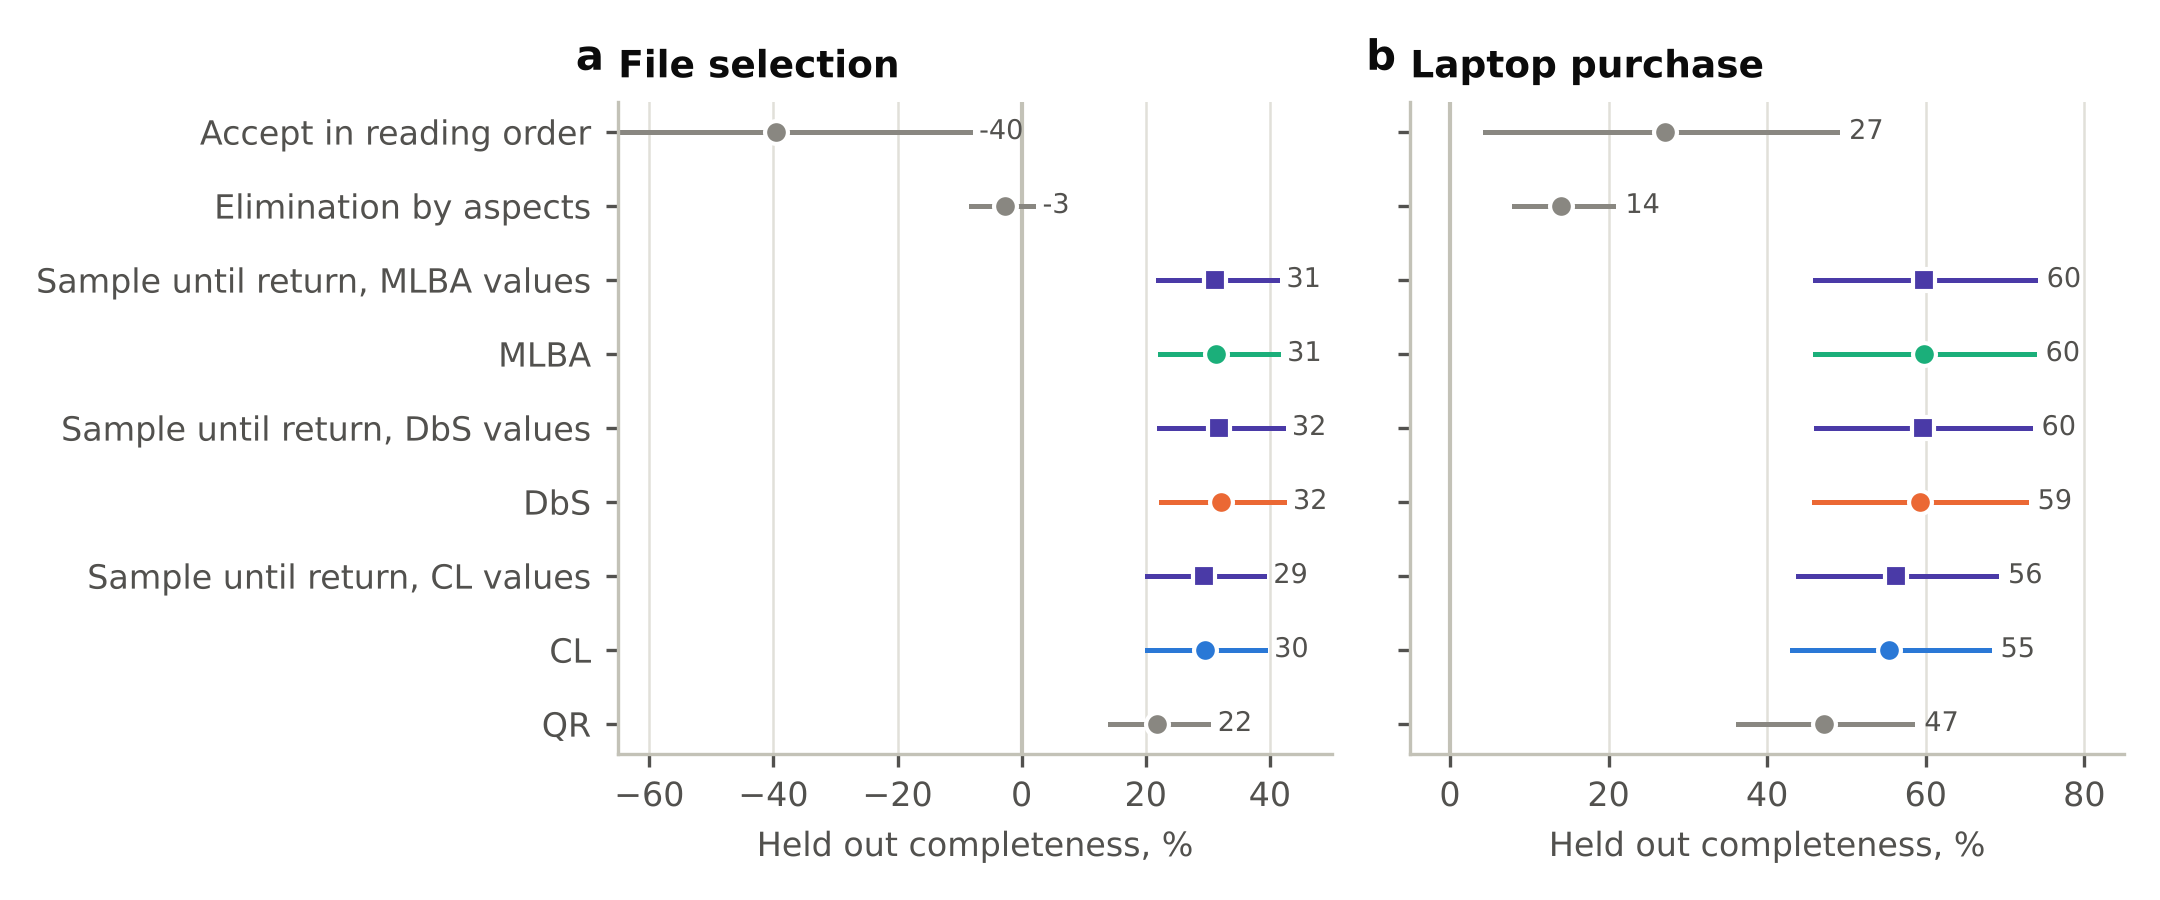

In [5]:
from overload.figures import figure_process_choices
display(Markdown(section(tables, "## 1. Choices", "## 2. Time, file")))
figure_process_choices(proc, out / "fig_choices")
display(Image(filename=str(out / "fig_choices.png"), width=900))

**Findings.**

1. With the same values, searching predicted choices as well as weighing everything. Sample until return on CL values reached 29.4 percent of the attainable for files and 56.2 percent for laptops, against CL's 29.5 and 55.4 (differences -0.1 [-0.3, 0.2] and +0.8 [0.3, 1.4]). On DbS values it reached 31.9 and 59.7 percent, against DbS's 32.1 and 59.3.
2. So the search model matched the best established models, DbS and MLBA, on choices, without beating them.
3. Accept in reading order failed badly (-39.5 percent for files and 27.2 for laptops), as did elimination by aspects (-2.7 and 14.0).
4. Of the models that predict choices well, the search model is the only one fast enough to be how people decided (Section 2).

**Message.** Choices cannot tell processes apart. Given the same values, a model that searches and stops predicts the same choices as one that weighs everything, but only the searcher is fast enough to be how people decided. Time and overload, not choices alone, are where process models must be judged.

## 4. Premonition. Can a model foresee overload before anyone chooses?

**Question.** From the display alone, and fits to other displays, can we tell which displays will overload people and on which they will choose poorly?

**Why it matters.** This is the practical payoff. A designer, a retailer or a defender could check a display before showing it.

**How.** Every forecast is computed from the display's options and from fits to the other displays, never from the display's own choices or answers.
- Feelings. Forecasts are the number of options, the attributes shown, each model's predicted spread of choices (entropy) and the search model's expected number of looks. A forecast is judged by how well it orders the displays by their overload index (rank correlation), and by the error of a held out calibration line against a forecast that ignores the display. This is done within each task and over both tasks together.
- Choice quality. Each model's expected regret, the shortfall of every option weighted by the model's predicted choice probabilities, is compared directly with people's mean regret.

With six displays per task, these rank correlations move in large steps, so they are read as descriptions.

## 3. Premonition, files

Overload index by trial: 2.19, 2.27, 2.43, 2.28, 2.65, 2.46. Constant forecast error 0.161 [0.108, 0.226] *.

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.96 [0.60, 0.96] * | 0.109 [0.055, 0.175] * | -0.052 [-0.106, 0.008] |
| attributes | -0.10 [-0.49, 0.10] | 0.180 [0.127, 0.254] * | +0.019 [0.004, 0.045] |
| looks_SR | +0.89 [0.60, 0.94] * | 0.110 [0.058, 0.176] * | -0.050 [-0.104, 0.009] |
| cells | +0.49 [-0.06, 0.52] | 0.170 [0.114, 0.253] * | +0.010 [-0.014, 0.051] |
| entropy_QR | +0.89 [0.43, 0.89] * | 0.113 [0.063, 0.180] * | -0.048 [-0.095, 0.011] |
| entropy_CL | +0.89 [0.60, 0.94] * | 0.107 [0.057, 0.172] * | -0.054 [-0.107, 0.006] |
| entropy_DbS_avg | +0.94 [0.71, 1.00] * | 0.101 [0.052, 0.164] * | -0.060 [-0.113, 0.000] |
| entropy_MLBA_avg | +0.94 [0.71, 1.00] * | 0.097 [0.049, 0.159] * | -0.064 [-0.119, -0.003] * |
| entropy_SR | +0.89 [0.60, 0.94] * | 0.108 [0.057, 0.173] * | -0.053 [-0.106, 0.007] |
| entropy_SR_DbS | +0.94 [0.71, 1.00] * | 0.100 [0.052, 0.163] * | -0.060 [-0.113, 0.000] |
| effort_CL | +0.49 [-0.06, 0.52] | 0.170 [0.114, 0.253] * | +0.010 [-0.014, 0.051] |
| effort_DbS_avg | +0.89 [0.43, 0.89] * | 0.262 [0.152, 0.376] * | +0.101 [0.007, 0.189] * |
| effort_EBA | +0.31 [-0.14, 0.43] | 0.251 [0.128, 0.392] * | +0.091 [0.007, 0.177] * |
| effort_SR | +0.37 [-0.14, 0.43] | 0.205 [0.130, 0.289] * | +0.044 [0.020, 0.066] * |

Regret by trial: 29.4, 15.7, 18.8, 28.3, 31.2, 26.5. Constant forecast error 6.16 [3.98, 8.56] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 15.7, 31.5, 17.1, 24.6, 25.7, 33.7 | -0.31 [-0.54, 0.26] | 7.92 [6.11, 10.17] * | +1.76 [-0.38, 4.25] |
| CL | 20.3, 27.7, 16.9, 17.8, 26.3, 31.7 | -0.09 [-0.43, 0.43] | 7.25 [5.50, 9.49] * | +1.09 [-1.08, 3.63] |
| DbS_avg | 18.8, 26.9, 17.2, 19.4, 29.8, 29.2 | +0.31 [-0.14, 0.66] | 6.04 [4.88, 8.43] * | -0.12 [-1.57, 3.04] |
| MLBA_avg | 19.3, 28.0, 18.5, 20.6, 32.4, 28.3 | +0.31 [-0.26, 0.60] | 5.56 [4.73, 8.18] * | -0.61 [-1.74, 2.90] |
| EBA | 29.4, 46.4, 30.2, 37.7, 54.2, 46.8 | +0.14 [-0.37, 0.60] | 15.78 [13.18, 19.09] * | +9.62 [6.63, 12.96] * |
| SR | 20.7, 28.6, 16.8, 18.2, 25.4, 31.2 | -0.09 [-0.43, 0.37] | 7.36 [5.54, 9.60] * | +1.19 [-0.98, 3.64] |
| SR_DbS | 19.2, 27.7, 17.2, 19.7, 29.0, 28.5 | +0.31 [-0.20, 0.60] | 6.11 [4.93, 8.47] * | -0.05 [-1.36, 2.92] |

## 3. Premonition, laptops

Overload index by trial: 1.81, 1.93, 1.90, 1.84, 2.02, 1.91. Constant forecast error 0.061 [0.040, 0.127].

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.53 [-0.15, 0.85] | 0.076 [0.036, 0.141] * | +0.015 [-0.044, 0.032] |
| attributes | +0.10 [-0.68, 0.49] | 0.081 [0.047, 0.157] * | +0.020 [-0.001, 0.035] |
| looks_SR | +0.66 [-0.03, 0.94] | 0.071 [0.036, 0.137] * | +0.010 [-0.047, 0.029] |
| cells | +0.44 [-0.35, 0.77] | 0.088 [0.046, 0.154] * | +0.027 [-0.018, 0.047] |
| entropy_QR | +0.37 [-0.31, 0.71] | 0.081 [0.041, 0.146] * | +0.020 [-0.032, 0.037] |
| entropy_CL | +0.66 [-0.03, 0.94] | 0.069 [0.034, 0.133] * | +0.008 [-0.044, 0.028] |
| entropy_DbS_avg | +0.66 [-0.03, 0.94] | 0.064 [0.029, 0.127] * | +0.003 [-0.053, 0.026] |
| entropy_MLBA_avg | +0.66 [0.03, 0.94] * | 0.059 [0.026, 0.122] | -0.002 [-0.062, 0.025] |
| entropy_SR | +0.66 [-0.03, 0.94] | 0.070 [0.033, 0.133] * | +0.009 [-0.044, 0.028] |
| entropy_SR_DbS | +0.66 [-0.03, 0.94] | 0.064 [0.029, 0.127] * | +0.003 [-0.053, 0.026] |
| effort_CL | +0.44 [-0.35, 0.77] | 0.088 [0.046, 0.154] * | +0.027 [-0.018, 0.047] |
| effort_DbS_avg | +0.49 [-0.31, 0.77] | 0.097 [0.046, 0.166] * | +0.036 [-0.008, 0.057] |
| effort_EBA | +0.26 [-0.49, 0.66] | 0.085 [0.044, 0.148] * | +0.024 [-0.016, 0.040] |
| effort_SR | +0.31 [-0.54, 0.60] | 0.076 [0.047, 0.147] * | +0.015 [-0.010, 0.036] |

Regret by trial: 22.5, 28.5, 28.3, 21.1, 15.2, 14.6. Constant forecast error 5.70 [4.45, 7.76] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 17.1, 18.9, 15.9, 27.7, 25.4, 25.0 | -0.60 [-0.77, -0.37] * | 9.11 [7.14, 11.00] * | +3.41 [1.72, 3.46] * |
| CL | 14.5, 25.0, 22.5, 21.3, 22.4, 22.5 | +0.20 [-0.20, 0.49] | 5.44 [4.16, 7.47] * | -0.26 [-1.27, 0.11] |
| DbS_avg | 16.0, 26.0, 21.3, 18.1, 23.8, 21.0 | +0.31 [-0.14, 0.37] | 5.68 [4.12, 7.46] * | -0.02 [-1.44, 0.63] |
| MLBA_avg | 19.2, 28.3, 20.7, 16.6, 25.0, 20.1 | +0.37 [-0.09, 0.37] | 5.14 [3.92, 7.13] * | -0.56 [-2.03, 0.81] |
| EBA | 31.4, 41.2, 25.5, 37.7, 33.3, 34.4 | +0.03 [-0.37, 0.26] | 13.13 [11.32, 14.99] * | +7.43 [4.99, 9.17] * |
| SR | 15.5, 25.8, 22.4, 21.4, 21.7, 21.8 | +0.43 [-0.06, 0.66] | 4.95 [3.72, 6.99] * | -0.75 [-1.75, -0.14] |
| SR_DbS | 17.0, 26.6, 21.2, 18.3, 23.2, 20.3 | +0.31 [-0.09, 0.37] | 5.18 [3.66, 6.99] * | -0.52 [-1.89, 0.32] |

## 3. Premonition, both tasks together

Overload index by trial: 2.19, 2.27, 2.43, 2.28, 2.65, 2.46, 1.81, 1.93, 1.90, 1.84, 2.02, 1.91. Constant forecast error 0.260 [0.172, 0.361] *.

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.41 [0.22, 0.52] * | 0.287 [0.177, 0.401] * | +0.026 [0.001, 0.038] * |
| attributes | -0.39 [-0.58, -0.30] * | 0.211 [0.149, 0.291] * | -0.049 [-0.084, -0.011] * |
| looks_SR | +0.52 [0.34, 0.63] * | 0.271 [0.167, 0.381] * | +0.011 [-0.013, 0.026] |
| cells | -0.13 [-0.35, -0.05] | 0.263 [0.184, 0.356] * | +0.003 [-0.014, 0.019] |
| entropy_QR | +0.53 [0.31, 0.64] * | 0.257 [0.165, 0.364] * | -0.004 [-0.026, 0.016] |
| entropy_CL | +0.52 [0.34, 0.63] * | 0.259 [0.157, 0.365] * | -0.001 [-0.029, 0.019] |
| entropy_DbS_avg | +0.57 [0.36, 0.71] * | 0.254 [0.155, 0.358] * | -0.006 [-0.036, 0.016] |
| entropy_MLBA_avg | +0.65 [0.38, 0.76] * | 0.249 [0.150, 0.351] * | -0.011 [-0.043, 0.013] |
| entropy_SR | +0.52 [0.34, 0.63] * | 0.257 [0.157, 0.363] * | -0.003 [-0.033, 0.018] |
| entropy_SR_DbS | +0.57 [0.36, 0.72] * | 0.252 [0.154, 0.356] * | -0.008 [-0.038, 0.015] |
| effort_CL | -0.13 [-0.35, -0.05] | 0.263 [0.184, 0.356] * | +0.003 [-0.014, 0.019] |
| effort_DbS_avg | +0.10 [-0.13, 0.19] | 0.289 [0.193, 0.394] * | +0.029 [0.019, 0.041] * |
| effort_EBA | +0.02 [-0.17, 0.15] | 0.322 [0.207, 0.450] * | +0.062 [0.031, 0.091] * |
| effort_SR | -0.27 [-0.50, -0.17] * | 0.243 [0.170, 0.329] * | -0.017 [-0.047, 0.008] |

Regret by trial: 29.4, 15.7, 18.8, 28.3, 31.2, 26.5, 22.5, 28.5, 28.3, 21.1, 15.2, 14.6. Constant forecast error 5.83 [4.67, 7.34] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 15.7, 31.5, 17.1, 24.6, 25.7, 33.7, 17.1, 18.9, 15.9, 27.7, 25.4, 25.0 | -0.32 [-0.55, 0.10] | 8.52 [7.25, 10.01] * | +2.68 [1.38, 3.98] * |
| CL | 20.3, 27.7, 16.9, 17.8, 26.3, 31.7, 14.5, 25.0, 22.5, 21.3, 22.4, 22.5 | +0.07 [-0.21, 0.39] | 6.35 [5.34, 7.89] * | +0.51 [-0.70, 2.01] |
| DbS_avg | 18.8, 26.9, 17.2, 19.4, 29.8, 29.2, 16.0, 26.0, 21.3, 18.1, 23.8, 21.0 | +0.22 [-0.08, 0.47] | 5.86 [5.02, 7.43] * | +0.03 [-1.16, 1.68] |
| MLBA_avg | 19.3, 28.0, 18.5, 20.6, 32.4, 28.3, 19.2, 28.3, 20.7, 16.6, 25.0, 20.1 | +0.36 [-0.04, 0.50] | 5.35 [4.82, 7.16] * | -0.49 [-1.50, 1.53] |
| EBA | 29.4, 46.4, 30.2, 37.7, 54.2, 46.8, 31.4, 41.2, 25.5, 37.7, 33.3, 34.4 | +0.09 [-0.19, 0.37] | 14.46 [12.84, 16.34] * | +8.62 [6.55, 10.61] * |
| SR | 20.7, 28.6, 16.8, 18.2, 25.4, 31.2, 15.5, 25.8, 22.4, 21.4, 21.7, 21.8 | +0.11 [-0.17, 0.48] | 6.15 [5.16, 7.70] * | +0.32 [-0.93, 1.81] |
| SR_DbS | 19.2, 27.7, 17.2, 19.7, 29.0, 28.5, 17.0, 26.6, 21.2, 18.3, 23.2, 20.3 | +0.22 [-0.08, 0.49] | 5.65 [4.86, 7.18] * | -0.19 [-1.35, 1.42] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero. Effort in elementary steps is in parentheses. Development data, exploratory.


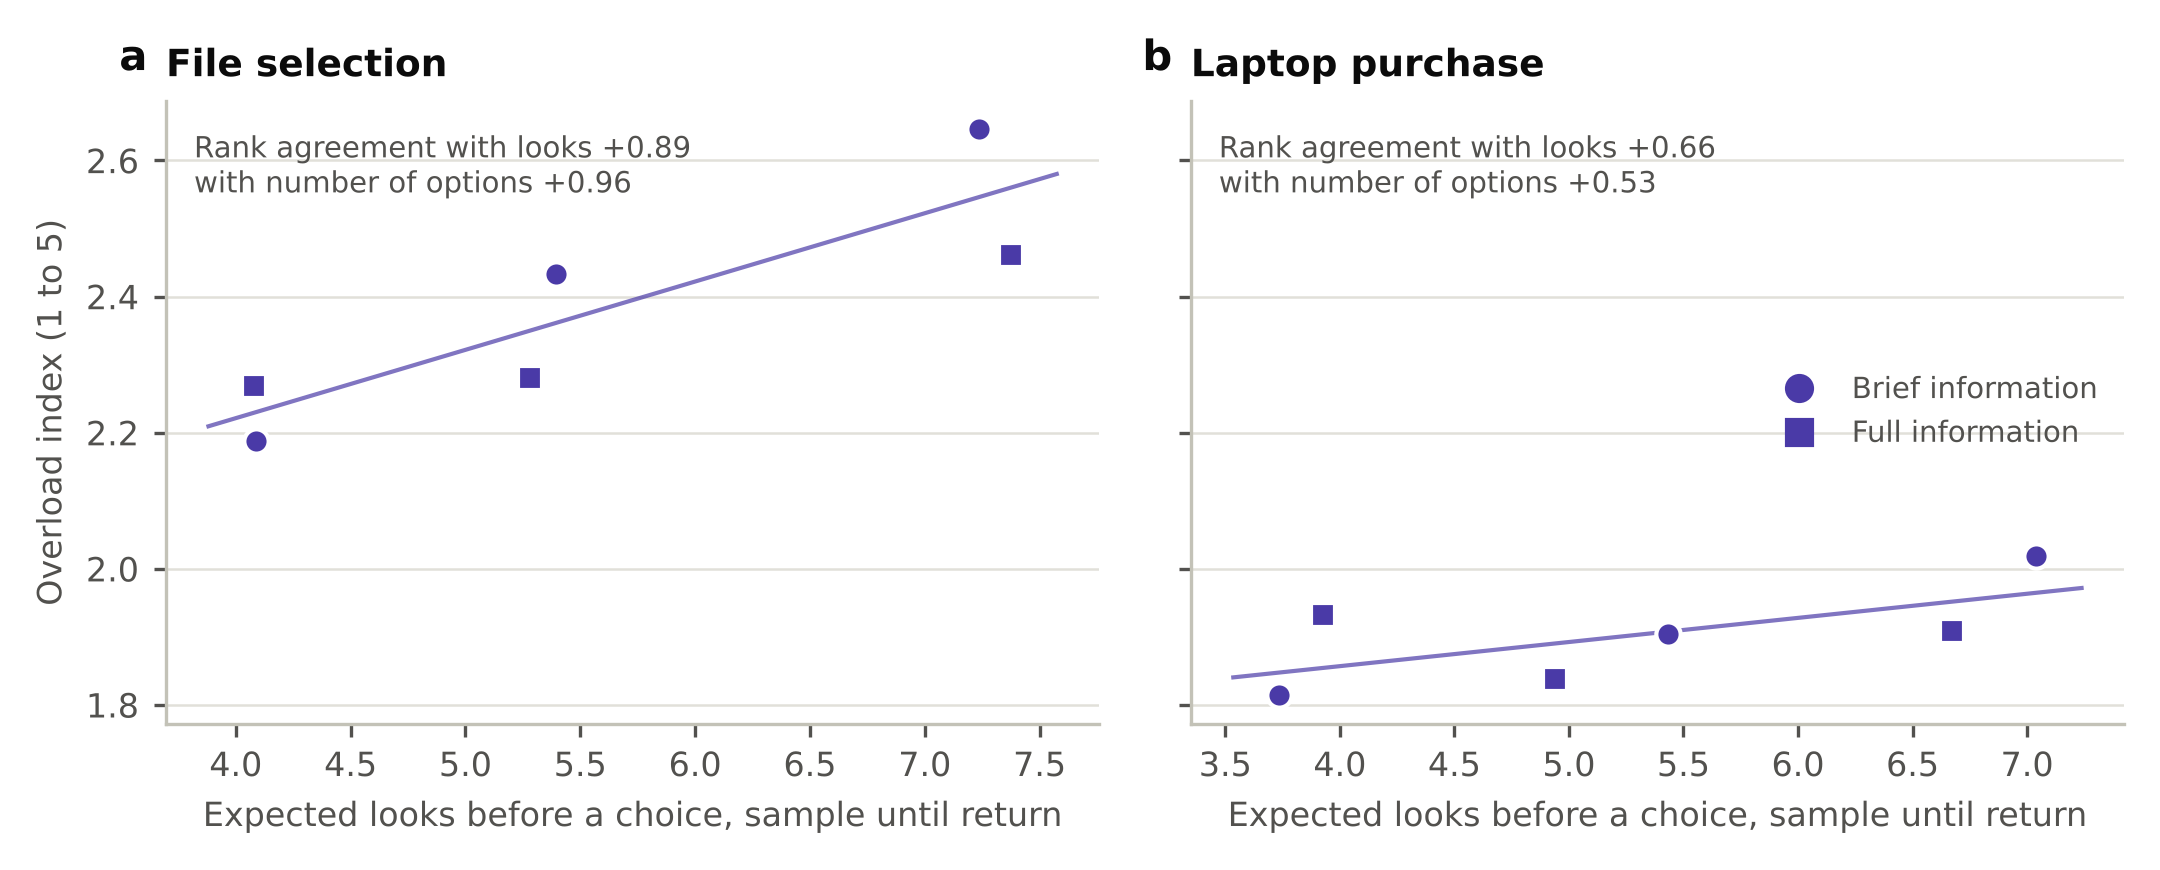

In [6]:
from overload.figures import figure_premonition
display(Markdown(section(tables, "## 3. Premonition, files")))
figure_premonition(proc, out / "fig_premonition")
display(Image(filename=str(out / "fig_premonition.png"), width=900))

**Findings.**

1. Within the file task, overload could be foreseen from the display. The number of options ordered the six file displays almost perfectly (rank correlation 0.96), and so did the models' forecasts of how spread the choices would be (0.89 to 0.94) and the search model's expected number of looks (0.89). Only MLBA's forecast beat a constant in held out error, by 0.064 scale points [0.003, 0.119].
2. Within the laptop task there was little to foresee, since overload stayed below average on every display.
3. No forecast foresaw the gap between the tasks. File and laptop displays of the same size drew similar forecasts but very different overload, so over all twelve displays no model forecast did better than a constant.
4. No model foresaw which displays would end in poor choices. Each model's expected regret predicted people's mean regret no better than a constant (an error of about 6 regret points). For laptops the search model came closest (4.9 against 5.7 points, not clear).

**Message.** Within a task, overload can be foreseen from the display, and the search model foresees it as well as counting options does. What made every file display overloading, not knowing what a file is worth, is in no model's forecast yet. With twelve displays this is as far as the development data go. The confirmatory tests move to open data with thousands of displays, where forecasts can be tested display by display.

## 5. Verification

**How.** Every result above was computed twice by the package, and the second run reproduced every saved value. An independent implementation, written blind from `verification/VERIFY_BRIEF_PROCESS.md` without access to the package, recomputed every value, and `verification/compare_process.py` compares the two value by value. The independent code is archived in `verification/independent_process`, and `sh verification/run_independent_process.sh PATH_TO_CSV` reruns it from scratch (about ten minutes).

In [7]:
indep = INDEPENDENT if INDEPENDENT.is_file() else REPO / "verification" / "independent_process" / "results.json"
r = subprocess.run([sys.executable, "verification/compare_process.py", "--independent", str(indep),
                    "--overload", "results/overload", "--process", "results/process_dev"],
                   cwd=REPO, capture_output=True, text=True)
print(r.stdout[-2600:] or r.stderr[-2600:])

Independent reimplementation against the package, overload, time, search models and premonition

Kind            checked   largest difference
association           9   0
clear               364   0
completeness         22   6.14e-07
completeness interval      88   1.67e-06
contrast             12   0
difference           20   6.14e-07
difference interval      80   1.58e-06
effort               96   6.21e-07
forecast            504   7.81e-07
forecast error      126   3.27e-09
forecast error interval     168   8.19e-09
forecast error p      42   0.002
interval           1008   6.85e-07
measurement           8   8.88e-16
outcome              48   0
p value             222   0
parameter           132   2.84e-07
per step             96   8.98e-08
regret error         63   3.29e-07
regret error interval      84   5.49e-07
regret error p       21   0
seconds              12   0
spearman             63   0
spearman interval     252   0.00682
spearman p           63   0.014
time error         

**Findings.**

1. The second run reproduced every saved value, including all 1000 resamples.
2. The independent implementation agreed on every value. Point values agreed to within 1e-6, and the fitted sensitivities of the search models to within 3e-7. In some resamples two forecasts that are equal up to 1e-7 were ranked differently by the two implementations, which moved a rank correlation bound by one step and a p value by a few resamples. No decision changed.
3. The verifier raised three points that shape the reading above. Combining both tasks mixes the gap between tasks into every forecast. Percentile intervals sit badly for rank correlations over six displays. Two file displays include timeouts at the 30 minute limit, 1.1 percent of the answers on each, recorded with the largest regret, and leaving them out changes no result.

## 6. What the development data say, and what comes next

- **Overload is display specific.** The same people were overloaded by large file displays and not by large laptop displays.
- **The clock rules out exhaustive comparison.** No model that compares every option with every other could have been as fast as people were.
- **A model that searches matches the best choice accuracy and is the only one fast enough.** Choices alone cannot tell processes apart, so the search model must prove itself on time, search and overload.
- **Premonition works within a task but not yet across tasks.** Twelve displays are too few to go further.

The confirmatory step tests the search model's predictions on open data it has never seen, frozen in advance by an amendment to the plan. The snack data of Thomas, Molter and Krajbich (2021) have thousands of random displays with response times and eye movements, so they test how search grows with the number of options, how long decisions take, and which displays will be slow or end in a poor choice, display by display.

## 7. The confirmatory test on the snack data (plan Amendment 5)

**Question.** Does the search model predict how people search, how long they take and what they choose, in data it has never seen?

**Why it matters.** The development data have only twelve displays, enough to build the model but not to test it. The snack data of Thomas, Molter and Krajbich (2021) have thousands of random displays of 9 to 36 snacks, each rated beforehand by the person choosing, with response times and eye movements. Their choices were used for H1, but their times and eye movements had never met a model.

**How.** Five tests were frozen in Amendment 5 before anything was run, and the analysis was run once. Every prediction comes from fits to the other three set sizes.
- **S1, search.** How the number of snacks looked at grows with set size, as an elasticity (1 means looking at every snack). Supported when people's growth is clearly below 1 and the model's predicted growth lies within 0.1 of it.
- **S2, time.** A time law, start up time plus time per step of the model's work, fitted on three set sizes and used to predict the response times of the fourth. Supported when the model's error is clearly below CL's and DbS's.
- **S3, slow decisions.** Within each person and set size, whether the trials the model expects to need more looks are the slow ones (rank correlation).
- **S4, missing the best.** How well each model foresees whether the chosen snack is the best rated one.
- **S5, choices.** Whether the model predicts the chosen snack at least as well as CL, the best static model on these data, to within 2 percent of the likelihood. Added at the author's request before the run. A design check (`scripts/simulate_choice_advantage.py`) showed that even if the search model were true, CL would trail it by less than 0.1 percent, so a tie is the expected outcome.

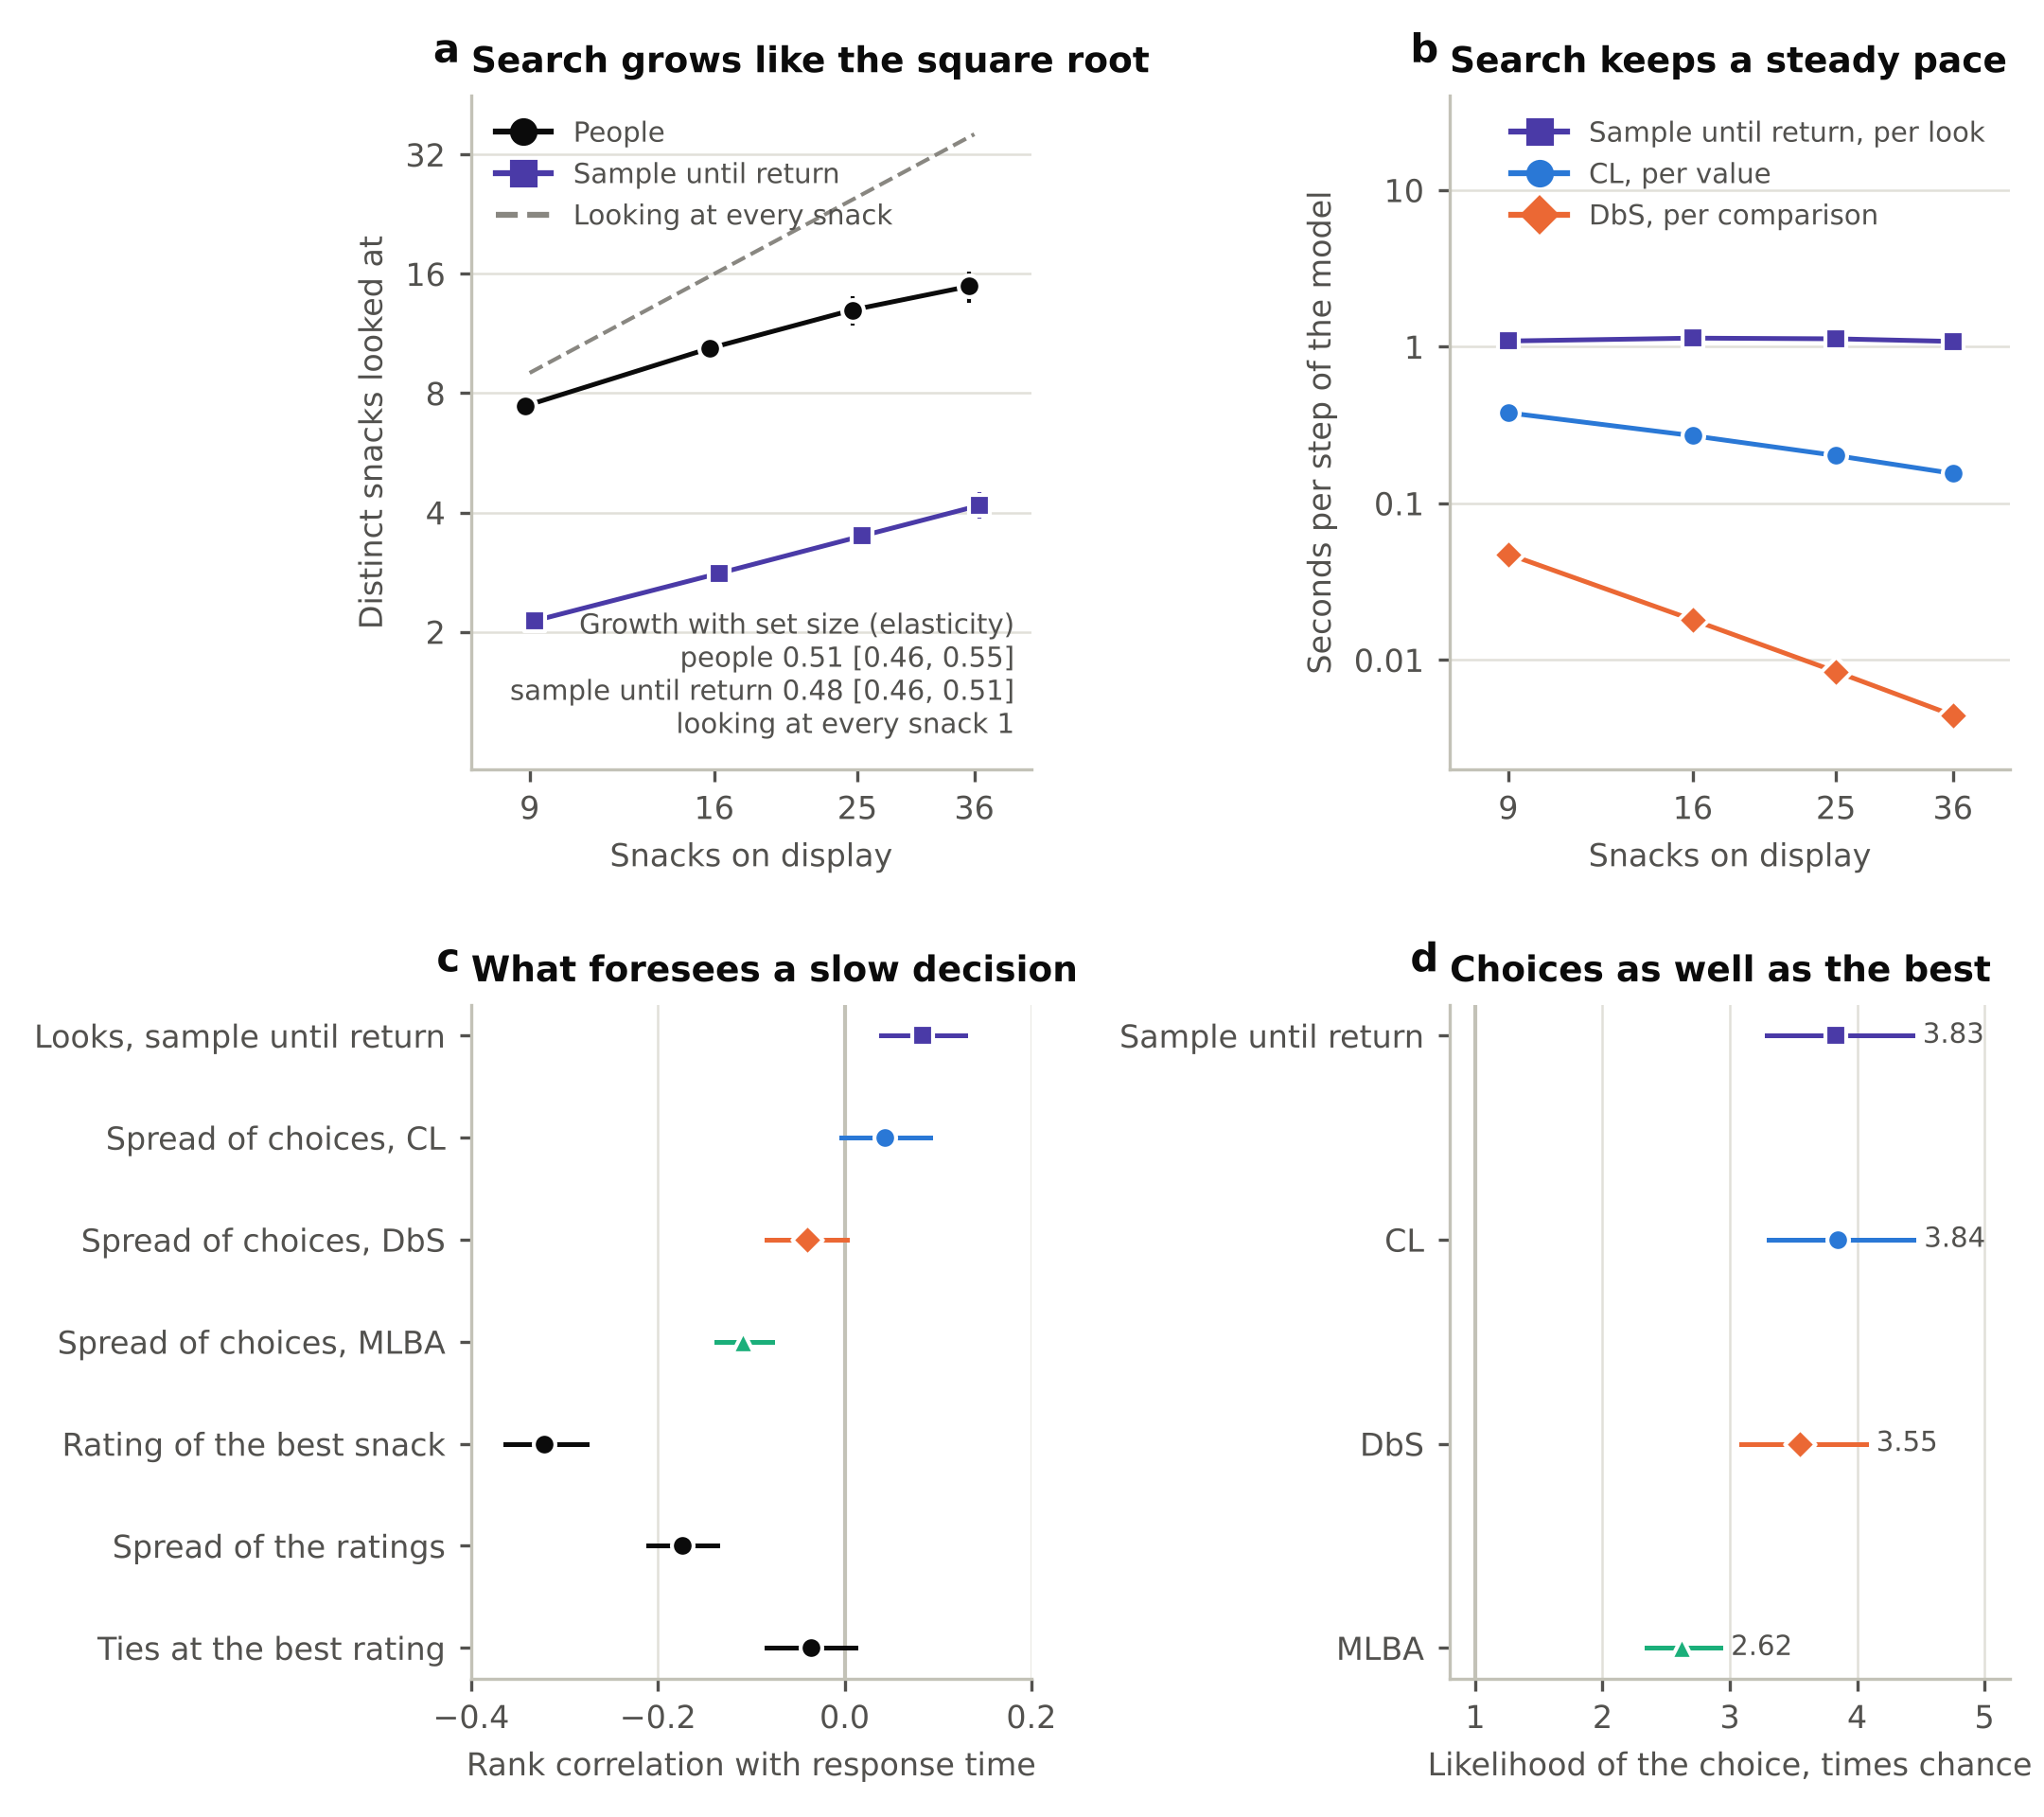

# Search model, confirmatory tests on the snack data (Amendment 5)

## S1, search grows sublinearly

| | 9 | 16 | 25 | 36 | Elasticity |
|---|---|---|---|---|---|
| Distinct items looked at, observed | 7.42 | 10.38 | 12.97 | 14.89 | 0.51 [0.46, 0.55] * |
| Predicted by sample until return | 2.13 | 2.81 | 3.49 | 4.17 | 0.48 [0.46, 0.51] * |
| Predicted by evaluating every item | 9 | 16 | 25 | 36 | 1 |
| Observed over predicted by sample until return | 3.48 | 3.69 | 3.72 | 3.57 | |

- Observed elasticity below one by 0.49 [0.45, 0.54] *.
- Predicted minus observed elasticity -0.02 [-0.07, 0.03], within the margin of 0.1 True. Supported True.

## S2, time held out (mean absolute error of log response time)

| Model | Error | 9 | 16 | 25 | 36 | Sample until return minus model |
|---|---|---|---|---|---|---|
| CL | 0.543 [0.498, 0.586] * | 0.485 | 0.523 | 0.576 | 0.589 | +0.009 [-0.003, 0.021] |
| DbS_avg | 0.550 [0.506, 0.592] * | 0.495 | 0.529 | 0.582 | 0.594 | +0.002 [-0.010, 0.015] |
| MLBA_avg | 0.550 [0.506, 0.592] * | 0.495 | 0.529 | 0.582 | 0.594 | +0.002 [-0.010, 0.015] |
| SR | 0.552 [0.504, 0.596] * | 0.500 | 0.521 | 0.582 | 0.607 |  |

Supported False.

## S3, premonition of slow decisions

| Forecast | Mean within participant rank correlation with response time |
|---|---|
| looks_SR | +0.084 [0.039, 0.129] * |
| entropy_CL | +0.043 [-0.004, 0.092] |
| entropy_DbS_avg | -0.040 [-0.083, 0.002] |
| entropy_MLBA_avg | -0.108 [-0.137, -0.078] * |
| top_rating | -0.322 [-0.364, -0.276] * |
| rating_sd | -0.174 [-0.210, -0.136] * |
| top_count | -0.036 [-0.084, 0.011] |

- Sample until return minus CL entropy +0.041 [0.030, 0.053] *. Supported True.

## S4, premonition of missing the best (bits per trial)

| Model | Log score | Minus constant |
|---|---|---|
| CL | -0.6651 [-0.7447, -0.5799] * | +0.0411 [0.0166, 0.0644] * |
| DbS_avg | -0.7704 [-0.8477, -0.6832] * | -0.0642 [-0.1060, -0.0227] * |
| MLBA_avg | -1.1472 [-1.2958, -1.0012] * | -0.4411 [-0.5842, -0.2936] * |
| SR | -0.6640 [-0.7445, -0.5771] * | +0.0422 [0.0169, 0.0663] * |
| constant | -0.7062 [-0.7799, -0.6235] * |  |

- Sample until return minus CL +0.0011 [-0.0017, 0.0037].

## S5, choices, held out likelihood of the chosen item relative to chance

- Sample until return minus CL -0.3 [-0.7, 0.0] percent (basic -0.7 to 0.0). Non inferior within 2 percent True, better False, worse False. Supported True.

## Secondary

Choices of every model, held out likelihood of the chosen item relative to chance.

| Model | Times chance | 9 | 16 | 25 | 36 | Sample until return minus model, % |
|---|---|---|---|---|---|---|
| CL | 3.84 [3.30, 4.45] | 2.86 | 3.64 | 4.37 | 4.80 | -0.3 [-0.7, 0.0] |
| DbS_avg | 3.55 [3.09, 4.07] | 2.64 | 3.48 | 4.03 | 4.28 | +8.0 [5.1, 11.0] * |
| MLBA_avg | 2.62 [2.35, 2.93] | 2.06 | 2.62 | 2.91 | 3.02 | +46.1 [30.6, 64.2] * |
| SR | 3.83 [3.29, 4.44] | 2.85 | 3.63 | 4.35 | 4.80 |  |

- Elasticity of CL's sensitivity implied by sample until return -0.010 [-0.032, 0.014] (observed in Amendment 3, +0.18).
- Time each step may take, median response time over mean effort, seconds, at 9, 16, 25 and 36 items. CL 0.378, 0.27, 0.202, 0.155; DbS_avg 0.0473, 0.018, 0.00841, 0.00443; SR 1.09, 1.13, 1.12, 1.08.

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


In [8]:
from overload.experiments import search_confirmatory
from overload.figures import figure_search_confirmatory
snack_dir = REPO / "data" / "snack"
if not (snack_dir / "setsize-36_desc-data.csv").exists():
    subprocess.run(["sh", "scripts/fetch_snack_data.sh", str(snack_dir)], cwd=REPO, check=True)
out = REPO / "results" / "search_confirmatory"
if RECOMPUTE or not (out / "summary.json").exists():
    search_confirmatory.run(snack_dir, out, replicates=1000, jobs=JOBS)  # about 15 minutes with two processes
conf = json.loads((out / "summary.json").read_text())
figure_search_confirmatory(conf, out / "fig_search_confirmatory")
display(Image(filename=str(out / "fig_search_confirmatory.png"), width=900))
display(Markdown((out / "table_search_confirmatory.md").read_text()))

**Findings.**

1. **Search grew like the square root of the number of options, as the model predicted.** People looked at 7.4 snacks when 9 were shown and 14.9 when 36 were shown, an elasticity of 0.51 [0.46, 0.55]. The model predicted 0.48 [0.46, 0.51], well inside the margin, so S1 was supported. A process that evaluates every item predicts 1.
2. **The model's searches were too short.** At every set size people looked at about 3.6 times as many snacks as the model. The growth is right and the level is not, so people return to options several times before they commit.
3. **The model's work kept pace with human time.** Median response time divided by the model's expected looks was 1.1 seconds at every set size. For CL the time per value would have to fall from 0.38 to 0.16 seconds as displays grew, and for DbS the time per comparison from 47 to 4 milliseconds.
4. **Single decisions were not timed better.** Held out, the time law built on the model's looks predicted log response times no better than one built on the number of options (error 0.552 against CL's 0.543, difference +0.009 [-0.003, 0.021]), so S2 was not supported.
5. **The model foresaw which decisions would be slow, though weakly.** Within a person and set size, its expected looks correlated +0.084 [0.039, 0.129] with response time, about twice CL's spread of choices (difference +0.041 [0.030, 0.053]), so S3 was supported. The strongest sign of a slow decision was something else. When the best snack on display was rated lower, people took longer (-0.32 [-0.36, -0.28]). The model reads only differences in value, so it cannot produce this.
6. **Choices were predicted as well as by the best model.** The chosen snack was 3.83 times as likely as chance under the model and 3.84 under CL, a difference of -0.3 percent [-0.7, 0.0], inside the 2 percent margin, so S5 was supported. The model beat DbS by 8.0 percent [5.1, 11.0] and MLBA by 46.1 percent [30.6, 64.2].
7. **Misses of the best snack were foreseen equally by the model and CL** (S4), both 0.04 bits per trial better than a constant forecast. DbS and MLBA did worse than the constant.

**Message.** People choose by a search whose length grows like the square root of what is on offer. A one parameter model of that search predicts choices as well as the best static model and is the only one whose work keeps pace with human time. What it lacks is an absolute standard. People stop sooner when something on display is really good, which points to the next version of the model and to a candidate for when choosing feels overwhelming, namely when nothing on display is good enough.

**Verification.** The analysis was run twice by the package, with identical results, and an independent implementation, written blind from `verification/VERIFY_BRIEF_SEARCH.md` and tested on simulated data before the real data were opened, recomputed every value. `verification/compare_search_confirmatory.py` compares them value by value, and `sh verification/run_independent_search.sh` reruns the independent code from scratch (about 20 minutes).

In [9]:
r = subprocess.run([sys.executable, "verification/compare_search_confirmatory.py",
                    "--independent", "verification/independent_search/results.json",
                    "--results", "results/search_confirmatory"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1600:] or r.stderr[-1600:])

Independent reimplementation against the package, search model on the snack data (Amendment 5)

Kind            checked   largest difference
choices              24   9.07e-09
clear                34   0
decision              8   0
interval            144   0.000412
p value              34   0.002
parameter            16   1.72e-08
premonition          10   2.19e-10
rank correlation       8   0.000174
search               16   3.13e-08
secondary            21   2.85e-08
time                 23   3.87e-09

Every value agrees within tolerance.



**Findings.** The two implementations agreed on every value and every decision. Outside the rank correlations the largest difference was 3e-7 (on the percent scale of S5), from locating the model's sensitivity to about 1e-8. Rank correlations differed by up to 4e-4, where two forecasts equal to within rounding were ranked in different orders. The verifier also reran the amendment's exact fitting procedure and found the same sensitivities to within 3e-8.

## 8. What the paper can now say

- **Overload is display specific.** The same people were overloaded by large file displays and not by large laptop displays (development data).
- **People search rather than weigh everything.** On the development displays, no model that compares every option with every other could have kept pace with people. On the snack data, the number of options people looked at grew like the square root of what was on offer, as the search model predicted before it saw these data.
- **Choices cannot reveal the process.** Given the same values, searching and weighing predict the same choices, in theory (the design check), on the development data and on the snack data. Process models therefore have to be judged on search and time, and there the search model is the only one consistent with people.
- **The search model is as accurate as the best model and paced like people, but it is not yet complete.** It stops too early and ignores how good the best option is in absolute terms.

**Next.** A search that stops at an option that is good enough in absolute terms would lengthen searches, speed decisions on displays with a clearly good option, and say when overload should arise. It was suggested by the snack data, so it must be tested on data it has not seen. Candidates are the gaze data of Thomas, Molter, Krajbich, Heekeren and Mohr (2019) and the search and satisficing data of Caplin, Dean and Martin (2011), whose values are money.